# Multiclass (MEL vs BCC vs SCC) con random undersampling (RUS): modelos de ML sobre las features

Igual que `ml_multiclass.ipynb` (que usa pesos de clase) pero tratando el desbalance con **remuestreo**. 3 clases desbalanceadas (~53 % MEL, ~39 % BCC, ~7 % SCC).

1. Carga de las features de `features_completes2/` filtrando los subtipos `mel`, `bcc`, `scc`.
2. CV estratificada de 5 folds en train: varios modelos, con **todas** las features y con **top-K** (selección con
   Random Forest **dentro de cada fold**), todo en paralelo (`N_JOBS` = cores − 2).
3. Train vs CV (overfitting) y ablación por familias.
4. Evaluación final en **val** (una sola vez): tabla de métricas, matrices de confusión, classification report.
5. Importancia por permutación y control de sesgo de adquisición (resolución).

**Desbalance: random undersampling (RUS).** En cada fold, *solo en el train del fold*, se eliminan al azar
imágenes de MEL y BCC hasta tener tantas como SCC. El fold de validación y `val` **no se tocan**.

- Cada modelo se entrena con solo ~3 × (nº de SCC) imágenes (≈ 21 % del train). Se pierde mucha información de MEL y
  BCC, así que es de esperar que empeoren esas clases. Sirve de referencia y es mucho más rápido.
- Para un término medio, `sampling_strategy` acepta un diccionario, p. ej. `{CLS2ID["mel"]: 1000, CLS2ID["bcc"]: 1000}`.
  Hay que definirlo después de cargar los datos.
- Sin `class_weight` ni `sample_weight`: con los datos ya equilibrados, los pesos corregirían el desbalance dos veces.
- La selección top-K (Random Forest con `class_weight="balanced_subsample"`) se ajusta con el train del fold **completo**,
  igual que en `ml_multiclass.ipynb`; solo los modelos ven el train reducido.

**Métricas:** la principal es **Cohen's kappa** (el desbalance hace que la accuracy engañe); también balanced accuracy,
F1 macro, AUC ROC one-vs-rest macro, **AUC precision-recall** (average precision, macro y por clase) y el
**recall de cada clase** (sobre todo SCC).

**Supuesto sobre los datos:** las imágenes del challenge multiclass (train ≈ 5082, val ≈ 1270) son las MEL/BCC/SCC
del dataset binario, que ya tienen features extraídas en `features_completes2/`. La celda de comprobación lo verifica
por nombre de archivo si existe la carpeta `Multiclass/<train|val>/`. Para el **test** habrá que pasar sus imágenes
por el mismo preprocesado y extracción de features.

**Ajustes para optimizar el kappa (nos evalúan por kappa):**
- **2b. Grid search** de los hiperparámetros de cada modelo (profundidad, nº de árboles / iteraciones, learning rate,
  C, vecinos...) con la **misma CV y el mismo pipeline** de este notebook (remuestreo incluido), eligiendo por kappa.
  Los mejores parámetros sustituyen a los de `MODELS` y se usan en todo lo demás.
- **4b. Ensembles** (media de probabilidades) de los mejores modelos, comparados por CV como uno más.
- **4c. Ajuste de la decisión por clase**: factores por clase que maximizan el kappa, elegidos con las predicciones
  out-of-fold de la CV (no con val) y aplicados en val.
- **6. Modelo final para el test**, reentrenado con train + val.

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, balanced_accuracy_score,
                             classification_report, cohen_kappa_score, f1_score, precision_recall_curve,
                             make_scorer, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import QuantileTransformer, label_binarize
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight

try:
    from imblearn.under_sampling import RandomUnderSampler
    from imblearn.pipeline import Pipeline as ImbPipeline     # aplica el sampler solo al entrenar (fit), nunca al predecir
except ImportError as e:
    raise ImportError("Falta imbalanced-learn: pip install imbalanced-learn (en el entorno del kernel)") from e

try:
    from xgboost import XGBClassifier
except Exception as e:      # ImportError, o versiones mezcladas de conda/pip (ValueError)
    import sys
    XGBClassifier = None
    print(f"AVISO: no se puede importar xgboost -> se omite XGBoost\n"
          f"  error: {type(e).__name__}: {e}\n  python del kernel: {sys.executable}")

warnings.filterwarnings("ignore")

# ---------------- Configuración ----------------
# ROOT = Path.cwd().parent if Path.cwd().name == "ml" else Path.cwd()
ROOT = Path(r"C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG")    # o fíjala a mano
assert (ROOT / "features_multiclass").exists(), f"ROOT incorrecta: {ROOT} (fíjala a mano arriba)"

TRAIN_CSV = ROOT / "features_multiclass" / "features_train.csv"
VAL_CSV   = ROOT / "features_multiclass" / "features_val.csv"
OUT_DIR   = ROOT / "ml" / "ml_results_multiclass_rus"      # carpeta propia: no pisa los resultados de los otros notebooks
CLASSES = ["bcc", "mel", "scc"]          # orden de las etiquetas 0, 1, 2
K_FEATURES = 50                          # top-K para la variante con selección
CV_FOLDS = 5
SEED = 42
N_JOBS = max(1, (os.cpu_count() or 1) - 2)          # todos los cores disponibles menos 2

RESAMPLING = "RUS"
SAMPLER = RandomUnderSampler(sampling_strategy="not minority", random_state=SEED)   # MEL y BCC hasta igualar a SCC
SCALE_ALL = False                                   # True: transformación cuantil en todos los modelos, antes del sampler
OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"ROOT: {ROOT}\ncores: {os.cpu_count()} -> N_JOBS = {N_JOBS}\nremuestreo: {SAMPLER}")

ROOT: C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG
cores: 28 -> N_JOBS = 26
remuestreo: RandomUnderSampler(random_state=42, sampling_strategy='not minority')


## 1. Carga de datos

In [2]:
tr_all, va_all = pd.read_csv(TRAIN_CSV), pd.read_csv(VAL_CSV)
tr = tr_all[tr_all["subtype"].isin(CLASSES)].reset_index(drop=True)
va = va_all[va_all["subtype"].isin(CLASSES)].reset_index(drop=True)

PREFIXES = ("shape_", "color_", "tex_", "gcolor_", "gtex_")
FEATS = [c for c in tr.columns if c.startswith(PREFIXES)]
assert FEATS == [c for c in va.columns if c.startswith(PREFIXES)], "train y val tienen columnas distintas"

CLS2ID = {c: i for i, c in enumerate(CLASSES)}
Xtr, ytr = tr[FEATS].replace([np.inf, -np.inf], np.nan), tr["subtype"].map(CLS2ID).to_numpy()
Xva, yva = va[FEATS].replace([np.inf, -np.inf], np.nan), va["subtype"].map(CLS2ID).to_numpy()
family = lambda c: c.split("_")[0]

counts = pd.DataFrame({"train": tr["subtype"].value_counts(), "val": va["subtype"].value_counts()}).reindex(CLASSES)
counts["train_%"] = (100 * counts["train"] / counts["train"].sum()).round(1)
counts["val_%"] = (100 * counts["val"] / counts["val"].sum()).round(1)
print(counts.to_string())
print(f"\ntrain: {Xtr.shape} | val: {Xva.shape} | NaN train {int(Xtr.isna().sum().sum())}, val {int(Xva.isna().sum().sum())}")
print("features por familia:", pd.Series([family(c) for c in FEATS]).value_counts().to_dict())

skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)
FAM_COLOR = {"shape": "#1f77b4", "color": "#d62728", "tex": "#2ca02c", "gcolor": "#ff9896", "gtex": "#98df8a"}

         train  val  train_%  val_%
subtype                            
bcc       1993  498     39.2   39.2
mel       2713  678     53.4   53.4
scc        376   94      7.4    7.4

train: (5082, 412) | val: (1270, 412) | NaN train 0, val 0
features por familia: {'tex': 104, 'gtex': 104, 'color': 82, 'gcolor': 70, 'shape': 52}


### Número de imágenes de cada clase
En train, en val y en cada fold de la CV (la división estratificada mantiene la proporción). También cuántas imágenes
de cada clase ve un modelo **después del remuestreo**, con el train del fold 1 como ejemplo. El remuestreo se rehace
en cada fold y en el entrenamiento final, siempre solo sobre train.

In [3]:
n_tr = tr["subtype"].value_counts().reindex(CLASSES)
n_va = va["subtype"].value_counts().reindex(CLASSES)

# lo que ve cada modelo tras el remuestreo, con el train del fold 1 de ejemplo (val no se toca nunca)
id2cls = dict(enumerate(CLASSES))
a0, _ = next(skf.split(np.zeros(len(ytr)), ytr))
Xa0 = SimpleImputer(strategy="median").fit_transform(Xtr.iloc[a0])
_, ya0_res = clone(SAMPLER).fit_resample(Xa0, ytr[a0])
n_f1 = pd.Series(ytr[a0]).map(id2cls).value_counts().reindex(CLASSES)
n_res = pd.Series(ya0_res).map(id2cls).value_counts().reindex(CLASSES)

summary = pd.DataFrame({"train": n_tr, "train_%": (100 * n_tr / n_tr.sum()).round(1),
                        "val": n_va, "val_%": (100 * n_va / n_va.sum()).round(1),
                        "fold1 train": n_f1, f"fold1 train tras {RESAMPLING}": n_res,
                        "factor": (n_res / n_f1).round(2)})
summary.loc["TOTAL"] = [n_tr.sum(), 100.0, n_va.sum(), 100.0, n_f1.sum(), n_res.sum(), round(n_res.sum() / n_f1.sum(), 2)]
print(summary.to_string(), "\n")

per_fold = pd.DataFrame({f"fold {f + 1} ({part})": pd.Series(ytr[idx]).map(id2cls).value_counts().reindex(CLASSES)
                         for f, (a, b) in enumerate(skf.split(np.zeros(len(ytr)), ytr))
                         for part, idx in (("train", a), ("val", b))})
print("Imágenes por clase en cada fold de la CV (antes de remuestrear):")
print(per_fold.to_string())

        train  train_%     val  val_%  fold1 train  fold1 train tras RUS  factor
bcc    1993.0     39.2   498.0   39.2       1594.0                 301.0    0.19
mel    2713.0     53.4   678.0   53.4       2170.0                 301.0    0.14
scc     376.0      7.4    94.0    7.4        301.0                 301.0    1.00
TOTAL  5082.0    100.0  1270.0  100.0       4065.0                 903.0    0.22 

Imágenes por clase en cada fold de la CV (antes de remuestrear):
     fold 1 (train)  fold 1 (val)  fold 2 (train)  fold 2 (val)  fold 3 (train)  fold 3 (val)  fold 4 (train)  fold 4 (val)  fold 5 (train)  fold 5 (val)
bcc            1594           399            1594           399            1594           399            1595           398            1595           398
mel            2170           543            2171           542            2171           542            2170           543            2170           543
scc             301            75             300            76   

### Comprobación: ¿son las mismas imágenes que las del challenge multiclass?
Si existe `Multiclass/<train|val>/<clase>/`, compara los nombres de archivo con los de las features.

In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
mc_dir = ROOT / "Multiclass"
checked = False
for split, df_ in (("train", tr), ("val", va)):
    d = next((p for p in mc_dir.iterdir() if p.is_dir() and p.name.lower().startswith(split)), None) if mc_dir.exists() else None
    if d is None:
        continue
    checked = True
    names = {f.stem for f in d.rglob("*") if f.suffix.lower() in IMG_EXT}
    ours = set(df_["name"])
    print(f"{split}: imágenes en Multiclass {len(names)} | con features {len(ours)} | comunes {len(names & ours)} | "
          f"solo en Multiclass {len(names - ours)} | solo en features {len(ours - names)}")
if not checked:
    print("No hay carpeta Multiclass/<train|val>/ con imágenes: no se puede comprobar.\n"
          "Los tamaños sí coinciden con el enunciado si train ≈ 5082 y val ≈ 1270.")

No hay carpeta Multiclass/<train|val>/ con imágenes: no se puede comprobar.
Los tamaños sí coinciden con el enunciado si train ≈ 5082 y val ≈ 1270.


## 2. Modelos y validación cruzada

- **Imputación** (mediana) → **top-K** con Random Forest (opcional) → **transformación cuantil** (modelos que la
  necesitan, o todos si `SCALE_ALL`) → **remuestreo** (`SAMPLER`, solo al entrenar) → modelo **sin pesos de clase**.
- Las métricas de train (para ver el overfitting) se calculan sobre el train del fold **original**, sin remuestrear.
- Igual que en el binario: la imputación y el top-K se ajustan una vez por fold (solo con el train del fold) y todos los
  pares **modelo × fold** se entrenan a la vez. Cada modelo usa 1 core para no pisarse con el paralelismo de fuera.
- `Dummy` predice siempre la misma clase (con el train equilibrado, la primera: BCC): kappa 0 y balanced accuracy
  0.33. Es el suelo.
- Para el SVM (sin `predict_proba`), el AUC se calcula con un softmax de `decision_function`.

In [5]:
MAIN = "kappa"                     # métrica para ordenar y elegir el mejor modelo
SCORING = ["kappa", "bal_acc", "f1_macro", "auc_ovr", "ap_macro"] + [f"recall_{c}" for c in CLASSES]

# sin class_weight / sample_weight: el desbalance ya lo corrige el remuestreo
MODELS = {   # nombre: (estimador, ¿necesita escalado?, ¿usa sample_weight balanceado?)
    "Dummy": (DummyClassifier(strategy="prior"), False, False),
    "LogReg (baseline)": (LogisticRegression(C=0.5, max_iter=5000), True, False),
    "KNN": (KNeighborsClassifier(n_neighbors=15, weights="distance"), True, False),
    "SVM-RBF": (SVC(C=1.0, gamma="scale"), True, False),
    "Decision Tree": (DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=SEED), False, False),
    "Random Forest": (RandomForestClassifier(n_estimators=400, min_samples_leaf=2, random_state=SEED, n_jobs=1), False, False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_depth=4,
                                                            early_stopping=False,
                                                            random_state=SEED), False, False),
}
if XGBClassifier is not None:
    MODELS["XGBoost"] = (XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=4, min_child_weight=3,
                                       subsample=0.8, colsample_bytree=0.5, reg_lambda=1.0, tree_method="hist",
                                       objective="multi:softprob", eval_metric="mlogloss", n_jobs=1,
                                       random_state=SEED), False, False)


def make_selector(k, n_jobs=1):
    """Top-k features según la importancia de un Random Forest (con pesos balanceados).
    Igual que en 03_v1_ml_multiclass.ipynb: se ajusta con el train del fold sin remuestrear."""
    est = RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
                                 class_weight="balanced_subsample", random_state=SEED, n_jobs=n_jobs)
    # est = ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
    #                            class_weight="balanced_subsample", random_state=SEED, n_jobs=n_jobs)  # más rápido
    return SelectFromModel(est, max_features=k, threshold=-np.inf)


def make_prep(k, n_jobs=1):
    steps = [("imp", SimpleImputer(strategy="median"))]
    if k:
        steps.append(("sel", make_selector(k, n_jobs=n_jobs)))
    return Pipeline(steps)


def make_head(model, scale):
    """[escalado] -> sampler -> modelo. ImbPipeline remuestrea solo en fit(); predict() no lo toca."""
    steps = [("scale", QuantileTransformer(n_quantiles=200, output_distribution="normal", random_state=SEED))] if (scale or SCALE_ALL) else []
    return ImbPipeline(steps + [("sampler", clone(SAMPLER)), ("clf", clone(model))])


def fit_head(model, scale, sw, X, y):
    warnings.filterwarnings("ignore")
    kw = {"clf__sample_weight": compute_sample_weight("balanced", y)} if sw else {}
    return make_head(model, scale).fit(X, y, **kw)


def predict_scores(est, X):
    """Probabilidades (n, 3). Si el modelo no tiene predict_proba (SVM), softmax de decision_function."""
    if hasattr(est, "predict_proba"):
        return est.predict_proba(X)
    d = est.decision_function(X)
    e = np.exp(d - d.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def mc_metrics(y, P, pred):
    rec = recall_score(y, pred, labels=list(range(len(CLASSES))), average=None, zero_division=0)
    out = {"kappa": cohen_kappa_score(y, pred), "bal_acc": balanced_accuracy_score(y, pred),
           "f1_macro": f1_score(y, pred, average="macro"),
           "auc_ovr": roc_auc_score(y, P, multi_class="ovr", average="macro", labels=list(range(len(CLASSES))))}
    Y = label_binarize(y, classes=list(range(len(CLASSES))))         # one-vs-rest
    ap = [average_precision_score(Y[:, j], P[:, j]) for j in range(len(CLASSES))]   # área bajo la curva PR
    out["ap_macro"] = float(np.mean(ap))
    out.update({f"recall_{c}": r for c, r in zip(CLASSES, rec)})
    out.update({f"ap_{c}": v for c, v in zip(CLASSES, ap)})
    return out


def _prep_fold(X, y, a, b, k, n_jobs=1):
    """Imputación (+ top-K) ajustada solo con el train del fold."""
    warnings.filterwarnings("ignore")
    p = make_prep(k, n_jobs=n_jobs).fit(X[a], y[a])
    return p.transform(X[a]), p.transform(X[b])


def _eval_fold(model, scale, sw, X, y, a, b, prepped=None):
    warnings.filterwarnings("ignore")
    if prepped is None:                       # sin top-K la imputación es instantánea: se hace aquí mismo
        prepped = _prep_fold(X, y, a, b, None)
    Xa, Xb = prepped
    m = fit_head(model, scale, sw, Xa, y[a])
    test = mc_metrics(y[b], predict_scores(m, Xb), m.predict(Xb))      # fold de validación (no visto)
    train = mc_metrics(y[a], predict_scores(m, Xa), m.predict(Xa))     # mismo train del fold (overfitting)
    return test | {f"train_{key}": v for key, v in train.items()}


def run_cv_many(subsets, k, models=MODELS, return_raw=False):
    """CV de varios subconjuntos de features x varios modelos, todo en paralelo.
    subsets: {nombre: X}. Devuelve una tabla indexada por (subconjunto, modelo) con media ± std de cada métrica."""
    y = ytr
    folds = list(skf.split(np.zeros(len(y)), y))
    Xs = {n: np.asarray(X, dtype=np.float64) for n, X in subsets.items()}
    prepped = {}
    if k:                                                  # 1) top-K una vez por (subconjunto, fold)
        keys = [(n, f) for n in Xs for f in range(len(folds))]
        inner = max(1, N_JOBS // len(keys))                # cores sobrantes -> árboles del RF selector
        out = Parallel(n_jobs=min(N_JOBS, len(keys)))(
            delayed(_prep_fold)(Xs[n], y, *folds[f], k, inner) for n, f in keys)
        prepped = dict(zip(keys, out))
    jobs = [(n, m, f) for n in Xs for m in models for f in range(len(folds))]   # 2) todos los modelo x fold a la vez
    res = Parallel(n_jobs=N_JOBS)(
        delayed(_eval_fold)(*models[m], None if k else Xs[n], y, *folds[f], prepped.get((n, f)))
        for n, m, f in jobs)
    df = pd.DataFrame(res).assign(subset=[j[0] for j in jobs], model=[j[1] for j in jobs])
    g = df.groupby(["subset", "model"], sort=False)[SCORING]
    mean, std = g.mean(), g.std(ddof=0)
    table = pd.DataFrame({m: mean[m].map("{:.3f}".format) + " ± " + std[m].map("{:.3f}".format) for m in SCORING})
    table["_main"] = mean[MAIN]
    return (table, df) if return_raw else table


def run_cv(X, k, models=MODELS, return_raw=False):
    table, raw = run_cv_many({"X": X}, k, models, return_raw=True)
    table = table.droplevel("subset").sort_values("_main", ascending=False)
    return (table, raw) if return_raw else table

### 2b. Ajuste de hiperparámetros (grid search por kappa)
Para cada modelo se prueban todas las combinaciones de su rejilla con la **misma CV estratificada de 5 folds** y el
**mismo pipeline** que en el resto del notebook (imputación → escalado → remuestreo / pesos → modelo), así que el
remuestreo se hace dentro de cada fold también aquí. Gana la combinación con mejor **kappa medio** y sustituye a los
parámetros de `MODELS`: la CV de abajo, la evaluación en val, los ensembles y los modelos guardados usan ya los
parámetros ajustados.

- Rejillas pequeñas y con sentido (~60 combinaciones en total): árboles poco o medio profundos, 200-600 iteraciones de
  boosting, learning rate 0.05-0.1, regularización de LogReg y SVM, nº de vecinos de KNN.
- En Random Forest no se ajusta el nº de árboles (más árboles nunca empeora, solo tarda más): se fija en 400 y se ajustan
  profundidad, tamaño mínimo de hoja y nº de features por división.
- Se ajusta con todas las features (`TUNE_ON = None`); en la variante top-K / PCA se reutilizan los mismos parámetros.
- El kappa de CV del modelo ajustado es un poco **optimista** (es el máximo de muchas combinaciones evaluadas en los mismos
  folds). La estimación honesta es **val**.
- `TUNE = True` hace la búsqueda y la guarda en `OUT_DIR/best_params.json`; con `TUNE = False` se cargan los parámetros de
  ese archivo (si existe) sin repetir la búsqueda.

In [6]:
import json
from itertools import product

TUNE = True            # True: grid search y guarda OUT_DIR/best_params.json | False: carga ese json (si no existe, parámetros por defecto)
TUNE_ON = None         # features con las que se ajusta (None = todas)

PARAM_GRIDS = {        # modelo: {parámetro: valores}. Combinaciones = producto de los tamaños
    "LogReg (baseline)": {"C": [0.01, 0.05, 0.2, 1.0, 5.0]},                                      # 5
    "KNN": {"n_neighbors": [5, 15, 31, 51], "weights": ["uniform", "distance"]},                  # 8
    "SVM-RBF": {"C": [0.3, 1.0, 3.0, 10.0]},                                                      # 4
    "Decision Tree": {"max_depth": [4, 6, 8, 12], "min_samples_leaf": [5, 20]},                   # 8
    "Random Forest": {"max_depth": [None, 15], "min_samples_leaf": [1, 3, 8],
                      "max_features": ["sqrt", 0.1]},                                              # 12
    "HistGradientBoosting": {"max_depth": [3, 5, 8], "learning_rate": [0.05, 0.1],
                             "max_iter": [200, 500]},                                              # 12
    "XGBoost": {"max_depth": [3, 5, 7], "learning_rate": [0.05, 0.1], "n_estimators": [300, 600]},  # 12
}

params_path = OUT_DIR / "best_params.json"
label = lambda p: ", ".join(f"{k}={v}" for k, v in p.items())

if TUNE:
    candidates, owner = {}, {}
    for m, grid in PARAM_GRIDS.items():
        if m not in MODELS:
            continue
        est, scale, sw = MODELS[m]
        for vals in product(*grid.values()):
            p = dict(zip(grid, vals))
            name = f"{m} | {label(p)}"
            candidates[name] = (clone(est).set_params(**p), scale, sw)
            owner[name] = (m, p)
    print(f"Grid search: {len(candidates)} combinaciones x {CV_FOLDS} folds = {len(candidates) * CV_FOLDS} entrenamientos "
          f"(elige por {MAIN}, N_JOBS = {N_JOBS})\n")
    t_grid = run_cv(Xtr, TUNE_ON, models=candidates)          # ordenada de mejor a peor por MAIN
    grid_res = pd.DataFrame({"modelo": [owner[n][0] for n in t_grid.index],
                             "parámetros": [label(owner[n][1]) for n in t_grid.index],
                             MAIN: t_grid["_main"].round(4).to_numpy(),
                             f"{MAIN} (media ± std)": t_grid[MAIN].to_numpy(),
                             "bal_acc": t_grid["bal_acc"].to_numpy(),
                             "recall_scc": t_grid["recall_scc"].to_numpy()}, index=t_grid.index)
    grid_res.to_csv(OUT_DIR / "grid_search.csv", index=False)
    best_params = {}
    for m in PARAM_GRIDS:
        sub = grid_res[grid_res["modelo"] == m]
        if len(sub) == 0:
            continue
        best_params[m] = owner[sub.index[0]][1]
        print(f"--- {m}: las 3 mejores de {len(sub)} ---")
        print(sub.drop(columns="modelo").head(3).to_string(index=False), "\n")
    params_path.write_text(json.dumps(best_params, indent=2), encoding="utf-8")
else:
    best_params = json.loads(params_path.read_text(encoding="utf-8")) if params_path.exists() else {}
    print(f"Parámetros cargados de {params_path}" if best_params else "No hay best_params.json: parámetros por defecto")

for m, p in best_params.items():                              # los mejores parámetros sustituyen a los de MODELS
    if m in MODELS:
        est, scale, sw = MODELS[m]
        MODELS[m] = (clone(est).set_params(**p), scale, sw)
print("Parámetros usados a partir de aquí:")
for m, p in best_params.items():
    print(f"  {m:<22s} {label(p)}")

Grid search: 61 combinaciones x 5 folds = 305 entrenamientos (elige por kappa, N_JOBS = 26)

--- LogReg (baseline): las 3 mejores de 5 ---
parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
    C=0.01 0.5649       0.565 ± 0.016 0.691 ± 0.019 0.593 ± 0.050
    C=0.05 0.5483       0.548 ± 0.013 0.685 ± 0.017 0.598 ± 0.044
     C=0.2 0.5313       0.531 ± 0.014 0.680 ± 0.016 0.614 ± 0.043 

--- KNN: las 3 mejores de 8 ---
                      parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
n_neighbors=15, weights=distance 0.4914       0.491 ± 0.020 0.655 ± 0.026 0.593 ± 0.078
 n_neighbors=15, weights=uniform 0.4914       0.491 ± 0.024 0.650 ± 0.030 0.564 ± 0.080
 n_neighbors=31, weights=uniform 0.4861       0.486 ± 0.019 0.633 ± 0.016 0.511 ± 0.042 

--- SVM-RBF: las 3 mejores de 4 ---
parámetros  kappa kappa (media ± std)       bal_acc    recall_scc
     C=3.0 0.5906       0.591 ± 0.016 0.729 ± 0.016 0.684 ± 0.039
    C=10.0 0.5759       0.576 ± 0.006 0.7

### CV con los modelos ajustados

In [7]:
print(f"CV {CV_FOLDS} folds en train ({len(Xtr)} imágenes), {len(MODELS)} modelos, remuestreo {RESAMPLING}, N_JOBS = {N_JOBS}\n")
res_all, raw_all = run_cv(Xtr, k=None, return_raw=True)
print(f"--- TODAS las features ({len(FEATS)}) ---")
print(res_all.drop(columns="_main").to_string(), "\n")

res_top, raw_top = run_cv(Xtr, k=K_FEATURES, return_raw=True)
print(f"--- TOP-{K_FEATURES} (selección dentro de cada fold) ---")
print(res_top.drop(columns="_main").to_string())

res_all.drop(columns="_main").to_csv(OUT_DIR / "cv_all_features.csv")
res_top.drop(columns="_main").to_csv(OUT_DIR / f"cv_top{K_FEATURES}.csv")

CV 5 folds en train (5082 imágenes), 8 modelos, remuestreo RUS, N_JOBS = 26

--- TODAS las features (412) ---
                              kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
model                                                                                                                                       
XGBoost               0.593 ± 0.020  0.722 ± 0.021  0.665 ± 0.015  0.902 ± 0.007  0.723 ± 0.013  0.698 ± 0.032  0.818 ± 0.022  0.649 ± 0.049
SVM-RBF               0.591 ± 0.016  0.729 ± 0.016  0.665 ± 0.012  0.891 ± 0.007  0.709 ± 0.019  0.694 ± 0.026  0.810 ± 0.014  0.684 ± 0.039
HistGradientBoosting  0.588 ± 0.011  0.728 ± 0.011  0.663 ± 0.008  0.901 ± 0.007  0.728 ± 0.013  0.695 ± 0.030  0.806 ± 0.018  0.684 ± 0.046
LogReg (baseline)     0.565 ± 0.016  0.691 ± 0.019  0.638 ± 0.012  0.886 ± 0.008  0.702 ± 0.022  0.671 ± 0.029  0.809 ± 0.018  0.593 ± 0.050
Random Forest         0.556 ± 0.031  0.704 ±

### ¿Hay overfitting? Train vs CV
Rendimiento sobre el mismo train con el que se entrena cada fold frente al fold de validación (sale de la celda anterior,
no se entrena nada nuevo). En Random Forest y XGBoost es normal que train esté cerca de 1.0; lo que manda es la CV.

In [8]:
def train_vs_cv(raw):
    g = raw.groupby("model", sort=False)
    t = pd.DataFrame({"train_kappa": g["train_kappa"].mean(), "cv_kappa": g["kappa"].mean(),
                      "train_bal_acc": g["train_bal_acc"].mean(), "cv_bal_acc": g["bal_acc"].mean(),
                      "train_recall_scc": g["train_recall_scc"].mean(), "cv_recall_scc": g["recall_scc"].mean()})
    t.insert(2, "gap_kappa", t["train_kappa"] - t["cv_kappa"])
    t.insert(5, "gap_bal_acc", t["train_bal_acc"] - t["cv_bal_acc"])
    return t.sort_values("cv_kappa", ascending=False).round(3)


ovf_all, ovf_top = train_vs_cv(raw_all), train_vs_cv(raw_top)
print(f"--- TODAS las features ({len(FEATS)}): train vs CV ---")
print(ovf_all.to_string(), "\n")
print(f"--- TOP-{K_FEATURES}: train vs CV ---")
print(ovf_top.to_string())
ovf_all.to_csv(OUT_DIR / "train_vs_cv_all_features.csv")
ovf_top.to_csv(OUT_DIR / f"train_vs_cv_top{K_FEATURES}.csv")

--- TODAS las features (412): train vs CV ---
                      train_kappa  cv_kappa  gap_kappa  train_bal_acc  cv_bal_acc  gap_bal_acc  train_recall_scc  cv_recall_scc
model                                                                                                                          
XGBoost                     0.702     0.593      0.110          0.868       0.722        0.146             1.000          0.649
SVM-RBF                     0.675     0.591      0.085          0.841       0.729        0.111             0.947          0.684
HistGradientBoosting        0.701     0.588      0.113          0.867       0.728        0.139             1.000          0.684
LogReg (baseline)           0.600     0.565      0.035          0.747       0.691        0.055             0.738          0.593
Random Forest               0.672     0.556      0.116          0.854       0.704        0.150             1.000          0.649
KNN                         0.613     0.491      0.121    

## 3. Ablación por familias
El mejor modelo de la CV (por kappa) con cada familia sola y combinadas (todas en paralelo). Ojo con las de **imagen entera** (`gcolor`, `gtex`):
pueden captar la cámara o el fondo en vez de la lesión.

In [9]:
ABL_MODEL = res_all.index[0]        # el mejor de la CV por kappa (todas las features)
fam_cols = {f: [c for c in FEATS if family(c) == f] for f in ["shape", "color", "tex", "gcolor", "gtex"]}
lesion = fam_cols["shape"] + fam_cols["color"] + fam_cols["tex"]
imagen = fam_cols["gcolor"] + fam_cols["gtex"]
subsets = {"solo forma": fam_cols["shape"], "solo color": fam_cols["color"], "solo textura": fam_cols["tex"],
           "solo gcolor": fam_cols["gcolor"], "solo gtex": fam_cols["gtex"],
           "forma + color": fam_cols["shape"] + fam_cols["color"], "color + textura": fam_cols["color"] + fam_cols["tex"],
           "lesión (shape+color+tex)": lesion, "imagen entera (gcolor+gtex)": imagen, "todas": FEATS}
abl = run_cv_many({name: Xtr[cols] for name, cols in subsets.items()}, k=None,
                  models={ABL_MODEL: MODELS[ABL_MODEL]}).droplevel("model")
abl.insert(0, "n_features", [len(c) for c in subsets.values()])
print(f"Ablación con {ABL_MODEL}\n")
print(abl.drop(columns="_main").to_string())
abl.drop(columns="_main").to_csv(OUT_DIR / "ablation_families.csv")

Ablación con XGBoost

                             n_features          kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
subset                                                                                                                                                         
solo forma                           52  0.381 ± 0.027  0.560 ± 0.020  0.523 ± 0.018  0.775 ± 0.013  0.571 ± 0.014  0.562 ± 0.025  0.672 ± 0.023  0.447 ± 0.020
solo color                           82  0.507 ± 0.013  0.673 ± 0.013  0.610 ± 0.008  0.864 ± 0.011  0.672 ± 0.014  0.612 ± 0.028  0.778 ± 0.018  0.628 ± 0.060
solo textura                        104  0.429 ± 0.011  0.615 ± 0.004  0.559 ± 0.004  0.815 ± 0.012  0.611 ± 0.020  0.550 ± 0.017  0.734 ± 0.009  0.561 ± 0.027
solo gcolor                          70  0.479 ± 0.015  0.653 ± 0.016  0.590 ± 0.009  0.852 ± 0.009  0.646 ± 0.015  0.599 ± 0.020  0.750 ± 0.010  0.609 ± 0.061
solo gtex         

## 4. Evaluación final en val
Se usa la variante de features (todas o top-K) que haya dado mejor kappa en la CV, sin mirar val. Cada modelo se entrena
con **todo train** (en paralelo) y se evalúa una sola vez en val. El IC95 % del kappa sale de un bootstrap sobre val.
El sampler solo sirve para entrenar, así que el pipeline final se guarda **sin** él (imputación → [top-K] →
[escalado] → modelo). Predice exactamente igual y para cargarlo no hace falta `imblearn`.

In [10]:
FINAL_K = None if res_all["_main"].iloc[0] >= res_top["_main"].iloc[0] else K_FEATURES
res_cv = res_all if FINAL_K is None else res_top
best = res_cv.index[0]                                  # mejor modelo según la CV (no según val)
print(f"Features para el modelo final: {'todas' if FINAL_K is None else f'top-{FINAL_K}'} | mejor en CV: {best}\n")


def boot_ci(y, pred, fn=cohen_kappa_score, n=1000, seed=0):
    rng = np.random.RandomState(seed)
    vals = [fn(y[i], pred[i]) for i in (rng.choice(len(y), len(y), replace=True) for _ in range(n))]
    return np.percentile(vals, [2.5, 97.5])


prep = make_prep(FINAL_K, n_jobs=N_JOBS).fit(Xtr, ytr)          # imputación (+ top-K) una sola vez
Xtr_s, Xva_s = prep.transform(Xtr), prep.transform(Xva)
heads = Parallel(n_jobs=N_JOBS)(delayed(fit_head)(est, scale, sw, Xtr_s, ytr) for est, scale, sw in MODELS.values())

fitted, rows, probas, preds = {}, [], {}, {}
for name, head in zip(MODELS, heads):
    pipe = Pipeline(prep.steps + [s for s in head.steps if s[0] != "sampler"])   # ya entrenado, sin el sampler (acepta las 420 columnas)
    P, pred = predict_scores(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, pred)
    fitted[name], probas[name], preds[name] = pipe, P, pred
    rows.append({"modelo": name, **mc_metrics(yva, P, pred), "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]"})
val_res = pd.DataFrame(rows).set_index("modelo").sort_values("kappa", ascending=False)
print(f"Val ({len(Xva)} imágenes):\n")
print(val_res.round(3).to_string())
val_res.round(4).to_csv(OUT_DIR / "val_results.csv")

Features para el modelo final: todas | mejor en CV: XGBoost

Val (1270 imágenes):

                      kappa  bal_acc  f1_macro  auc_ovr  ap_macro  recall_bcc  recall_mel  recall_scc  ap_bcc  ap_mel  ap_scc     kappa IC95%
modelo                                                                                                                                       
HistGradientBoosting  0.606    0.763     0.682    0.908     0.747       0.721       0.791       0.777   0.862   0.940   0.438  [0.569, 0.645]
SVM-RBF               0.601    0.752     0.673    0.898     0.722       0.701       0.801       0.755   0.850   0.944   0.373  [0.565, 0.641]
XGBoost               0.579    0.725     0.656    0.899     0.734       0.699       0.786       0.691   0.861   0.939   0.403  [0.543, 0.617]
LogReg (baseline)     0.559    0.689     0.632    0.883     0.681       0.655       0.807       0.606   0.862   0.942   0.238  [0.524, 0.596]
Random Forest         0.552    0.703     0.636    0.879     0.711

### 4b. Ensembles (soft voting) de los mejores modelos
Cada miembro da sus probabilidades para BCC / MEL / SCC, se promedian (con pesos si se indican) y gana la clase con la
media más alta. Un ensemble mejora cuando sus miembros se equivocan en imágenes **distintas**: XGBoost y HGB son muy
parecidos (fallan en lo mismo), mientras que SVM y LogReg aportan más diversidad y recuperan más SCC.

- Variantes (`ENSEMBLES`): XGB+HGB+SVM, HGB+SVM, HGB+SVM con el SVM pesando el doble, y HGB+SVM+LogReg. Los miembros
  usan los **parámetros ajustados** en 2b.
- Mismo pipeline que el resto (el remuestreo se hace una vez y todos los miembros entrenan con los mismos datos).
- El SVM de los ensembles usa `probability=True` (calibración de Platt con una CV interna: ~5× más lento que el SVM normal).
- Se evalúan **por CV** (`ENS_CV = True`) igual que los demás y se añaden a la tabla de val y a las matrices de confusión.
  `best` pasa a ser el mejor de la CV contando también los ensembles (nunca se elige mirando val).

In [11]:
from sklearn.ensemble import VotingClassifier

ENSEMBLES = {          # nombre: (miembros, pesos o None = media simple)
    "Ens XGB+HGB+SVM": (["XGBoost", "HistGradientBoosting", "SVM-RBF"], None),
    "Ens HGB+SVM": (["HistGradientBoosting", "SVM-RBF"], None),
    "Ens HGB+SVM (SVM x2)": (["HistGradientBoosting", "SVM-RBF"], [1, 2]),
    "Ens HGB+SVM+LogReg": (["HistGradientBoosting", "SVM-RBF", "LogReg (baseline)"], None),
}
ENS_CV = True          # True: CV de 5 folds de cada ensemble (para compararlos con los demás por CV)


def make_ensemble(members, weights=None):
    members = [m for m in members if m in MODELS]          # XGBoost puede no estar instalado
    sw = any(MODELS[m][2] for m in members)               # si un miembro usa sample_weight (v1: XGBoost), lo usan todos...
    ests = []
    for m in members:
        est = clone(MODELS[m][0])
        if isinstance(est, SVC):                           # soft voting necesita predict_proba
            est.set_params(probability=True, random_state=SEED)
        if sw and "class_weight" in est.get_params():      # ...y se quita class_weight para no corregir el desbalance dos veces
            est.set_params(class_weight=None)
        ests.append(("".join(ch for ch in m.lower() if ch.isalnum()), est))
    w = weights if weights is not None and len(weights) == len(ests) else None
    return VotingClassifier(ests, voting="soft", weights=w), True, sw


ENS_SPECS = {name: make_ensemble(*cfg) for name, cfg in ENSEMBLES.items()}
ALL_SPECS = {**MODELS, **ENS_SPECS}                        # para reentrenar el mejor, sea modelo o ensemble
ENS_MEMBERS = [m for m in MODELS if any(m in ms for ms, _ in ENSEMBLES.values())]
print(f"Ensembles: {list(ENS_SPECS)} | features: {('todas' if FINAL_K is None else f'top-{FINAL_K}')}\n")

# 1) CV de 5 folds (mismos folds y features que el modelo final)
if ENS_CV:
    t_ens = run_cv(Xtr, FINAL_K, models=ENS_SPECS)
    res_cv = pd.concat([res_cv.drop(index=list(ENS_SPECS), errors="ignore"), t_ens]).sort_values("_main", ascending=False)
    print("CV (media ± std de 5 folds): miembros y ensembles")
    print(res_cv.loc[ENS_MEMBERS + list(ENS_SPECS)].sort_values("_main", ascending=False)
          .drop(columns="_main").to_string(), "\n")

# 2) entrenar con todo train y evaluar en val (una vez)
heads = Parallel(n_jobs=min(N_JOBS, len(ENS_SPECS)))(
    delayed(fit_head)(*spec, Xtr_s, ytr) for spec in ENS_SPECS.values())
rows = []
for name, head in zip(ENS_SPECS, heads):
    pipe = Pipeline(prep.steps + [s for s in head.steps if s[0] != "sampler"])     # sin el sampler, como los demás
    P, pred = predict_scores(pipe, Xva), pipe.predict(Xva)
    lo, hi = boot_ci(yva, pred)
    fitted[name], probas[name], preds[name] = pipe, P, pred
    rows.append({"modelo": name, **mc_metrics(yva, P, pred), "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]"})
val_res = (pd.concat([val_res.drop(index=list(ENS_SPECS), errors="ignore"),
                      pd.DataFrame(rows).set_index("modelo")[val_res.columns]])
           .rename_axis("modelo").sort_values("kappa", ascending=False))
val_res.round(4).to_csv(OUT_DIR / "val_results.csv")

cols = ["kappa", "kappa IC95%", "bal_acc", "f1_macro", "auc_ovr", "ap_macro"] + [f"recall_{c}" for c in CLASSES]
cmp = val_res.loc[ENS_MEMBERS + list(ENS_SPECS), cols].copy()
if ENS_CV:
    cmp.insert(0, "cv_kappa", res_cv.loc[cmp.index, "_main"])
    cmp = cmp.sort_values("cv_kappa", ascending=False)
print(f"Val ({len(Xva)} imágenes): miembros y ensembles (ordenados por kappa de CV)\n")
print(cmp.round(3).to_string(), "\n")

# 3) el mejor según la CV, contando los ensembles (no se elige mirando val)
best = res_cv.index[0]
print(f"Mejor en CV ({MAIN} {res_cv['_main'].iloc[0]:.3f}): best = {best}")

Ensembles: ['Ens XGB+HGB+SVM', 'Ens HGB+SVM', 'Ens HGB+SVM (SVM x2)', 'Ens HGB+SVM+LogReg'] | features: todas

CV (media ± std de 5 folds): miembros y ensembles
                              kappa        bal_acc       f1_macro        auc_ovr       ap_macro     recall_bcc     recall_mel     recall_scc
model                                                                                                                                       
Ens HGB+SVM (SVM x2)  0.602 ± 0.021  0.733 ± 0.016  0.673 ± 0.014  0.907 ± 0.008  0.738 ± 0.020  0.707 ± 0.028  0.818 ± 0.022  0.676 ± 0.034
Ens HGB+SVM+LogReg    0.600 ± 0.018  0.733 ± 0.017  0.670 ± 0.013  0.907 ± 0.007  0.733 ± 0.019  0.703 ± 0.029  0.817 ± 0.021  0.678 ± 0.044
Ens XGB+HGB+SVM       0.594 ± 0.016  0.728 ± 0.014  0.666 ± 0.011  0.908 ± 0.007  0.738 ± 0.016  0.701 ± 0.022  0.812 ± 0.022  0.670 ± 0.035
Ens HGB+SVM           0.593 ± 0.018  0.727 ± 0.014  0.665 ± 0.012  0.906 ± 0.008  0.738 ± 0.019  0.700 ± 0.032  0.812 ± 0.018  0.670 ±

### 4c. Ajuste de la decisión por clase (para maximizar el kappa)
Ahora se predice la clase con la probabilidad más alta (argmax). Con clases desbalanceadas eso no tiene por qué ser lo que
maximiza el kappa. Aquí se multiplica la probabilidad de cada clase por un factor (`w_bcc`, `w_scc`; MEL fijo en 1) antes
del argmax: si `w_scc > 1`, el modelo predice SCC con menos seguridad, y al revés.

1. **Probabilidades out-of-fold** del mejor modelo (`best`): cada imagen de train la predice el modelo del fold en el que
   **no** se entrenó. Es exactamente la CV, pero guardando las predicciones.
2. Se prueban los factores de `W_GRID` para BCC y SCC y se elige la pareja con mejor kappa sobre esas predicciones.
3. Los factores se aplican **tal cual** al modelo final en val. Val no interviene en la elección, así que la comparación
   argmax vs. con factores en val es honesta.

No hace falta reentrenar nada: solo cambia la regla de decisión. Los factores se guardan en
`OUT_DIR/decision_weights.json` y se usan también con el modelo final para el test (sección 6).

Modelo: Ens HGB+SVM (SVM x2)
Factores por clase: {'bcc': np.float64(1.9), 'mel': np.float64(1.0), 'scc': np.float64(0.5)}
CV out-of-fold: kappa 0.602 (argmax) -> 0.649 (con factores)

Val (1270 imágenes), Ens HGB+SVM (SVM x2):

              kappa     kappa IC95%  bal_acc  f1_macro  recall_bcc  recall_mel  recall_scc
decisión                                                                                  
argmax        0.617  [0.581, 0.655]    0.770     0.687       0.721       0.801       0.787
con factores  0.645  [0.605, 0.683]    0.703     0.686       0.867       0.794       0.447


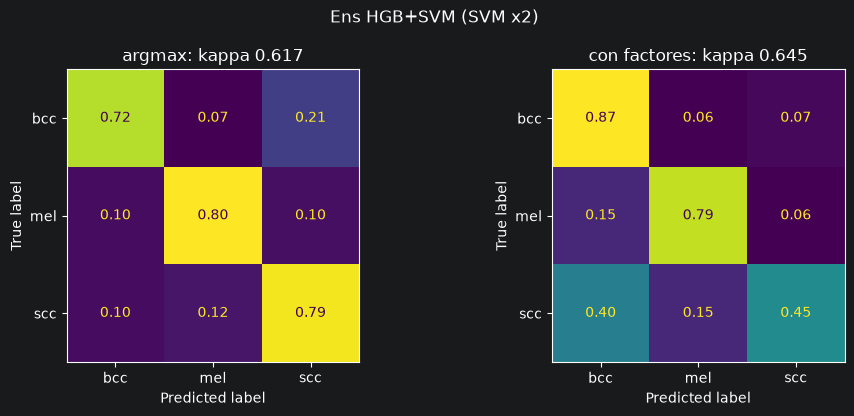

135

In [12]:
from itertools import product

TUNE_DECISION = True
W_GRID = np.round(np.arange(0.5, 3.01, 0.1), 2)        # factores a probar para BCC y SCC (MEL = 1)


def _oof_fold(spec, X, y, a, b):
    warnings.filterwarnings("ignore")
    Xa, Xb = _prep_fold(X, y, a, b, FINAL_K)
    m = fit_head(*spec, Xa, y[a])
    return b, predict_scores(m, Xb)


def oof_proba(spec):
    """Probabilidades out-of-fold (n_train, 3) con los mismos folds que la CV."""
    X = np.asarray(Xtr, dtype=np.float64)
    folds = list(skf.split(np.zeros(len(ytr)), ytr))
    out = Parallel(n_jobs=min(N_JOBS, len(folds)))(delayed(_oof_fold)(spec, X, ytr, a, b) for a, b in folds)
    P = np.zeros((len(ytr), len(CLASSES)))
    for b, Pb in out:
        P[b] = Pb
    return P


def apply_w(P, w):
    return np.argmax(P * np.asarray(w, dtype=float), axis=1)


def best_weights(P, y, fn=cohen_kappa_score):
    ref = CLASSES.index("mel")
    others = [j for j in range(len(CLASSES)) if j != ref]
    best_w = np.ones(len(CLASSES))
    best_s = fn(y, apply_w(P, best_w))
    for vals in product(W_GRID, repeat=len(others)):
        w = np.ones(len(CLASSES))
        w[others] = vals
        s = fn(y, apply_w(P, w))
        if s > best_s + 1e-9:
            best_w, best_s = w, s
    return best_w, best_s


DECISION_W = np.ones(len(CLASSES))
if TUNE_DECISION:
    P_oof = oof_proba(ALL_SPECS[best])
    k_arg = cohen_kappa_score(ytr, P_oof.argmax(1))
    DECISION_W, k_w = best_weights(P_oof, ytr)
    print(f"Modelo: {best}")
    print(f"Factores por clase: {dict(zip(CLASSES, DECISION_W.round(2)))}")
    print(f"CV out-of-fold: kappa {k_arg:.3f} (argmax) -> {k_w:.3f} (con factores)\n")

    P = probas[best]
    rows = []
    for lab, pr in [("argmax", preds[best]), ("con factores", apply_w(P, DECISION_W))]:
        lo, hi = boot_ci(yva, pr)
        m = mc_metrics(yva, P, pr)
        rows.append({"decisión": lab, "kappa": m["kappa"], "kappa IC95%": f"[{lo:.3f}, {hi:.3f}]",
                     "bal_acc": m["bal_acc"], "f1_macro": m["f1_macro"], **{f"recall_{c}": m[f"recall_{c}"] for c in CLASSES}})
    dec_res = pd.DataFrame(rows).set_index("decisión")
    print(f"Val ({len(Xva)} imágenes), {best}:\n")
    print(dec_res.round(3).to_string())
    dec_res.round(4).to_csv(OUT_DIR / "val_decision_weights.csv")

    fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
    for ax, (lab, pr) in zip(axs, [("argmax", preds[best]), ("con factores", apply_w(P, DECISION_W))]):
        ConfusionMatrixDisplay.from_predictions(yva, pr, labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                                normalize="true", values_format=".2f", ax=ax, colorbar=False)
        ax.set_title(f"{lab}: kappa {cohen_kappa_score(yva, pr):.3f}")
    plt.suptitle(best); plt.tight_layout(); plt.show()

(OUT_DIR / "decision_weights.json").write_text(
    json.dumps({"model": best, "classes": CLASSES, "weights": DECISION_W.tolist()}, indent=2), encoding="utf-8")

### Matrices de confusión de todos los modelos (val, normalizadas por fila = recall de cada clase)

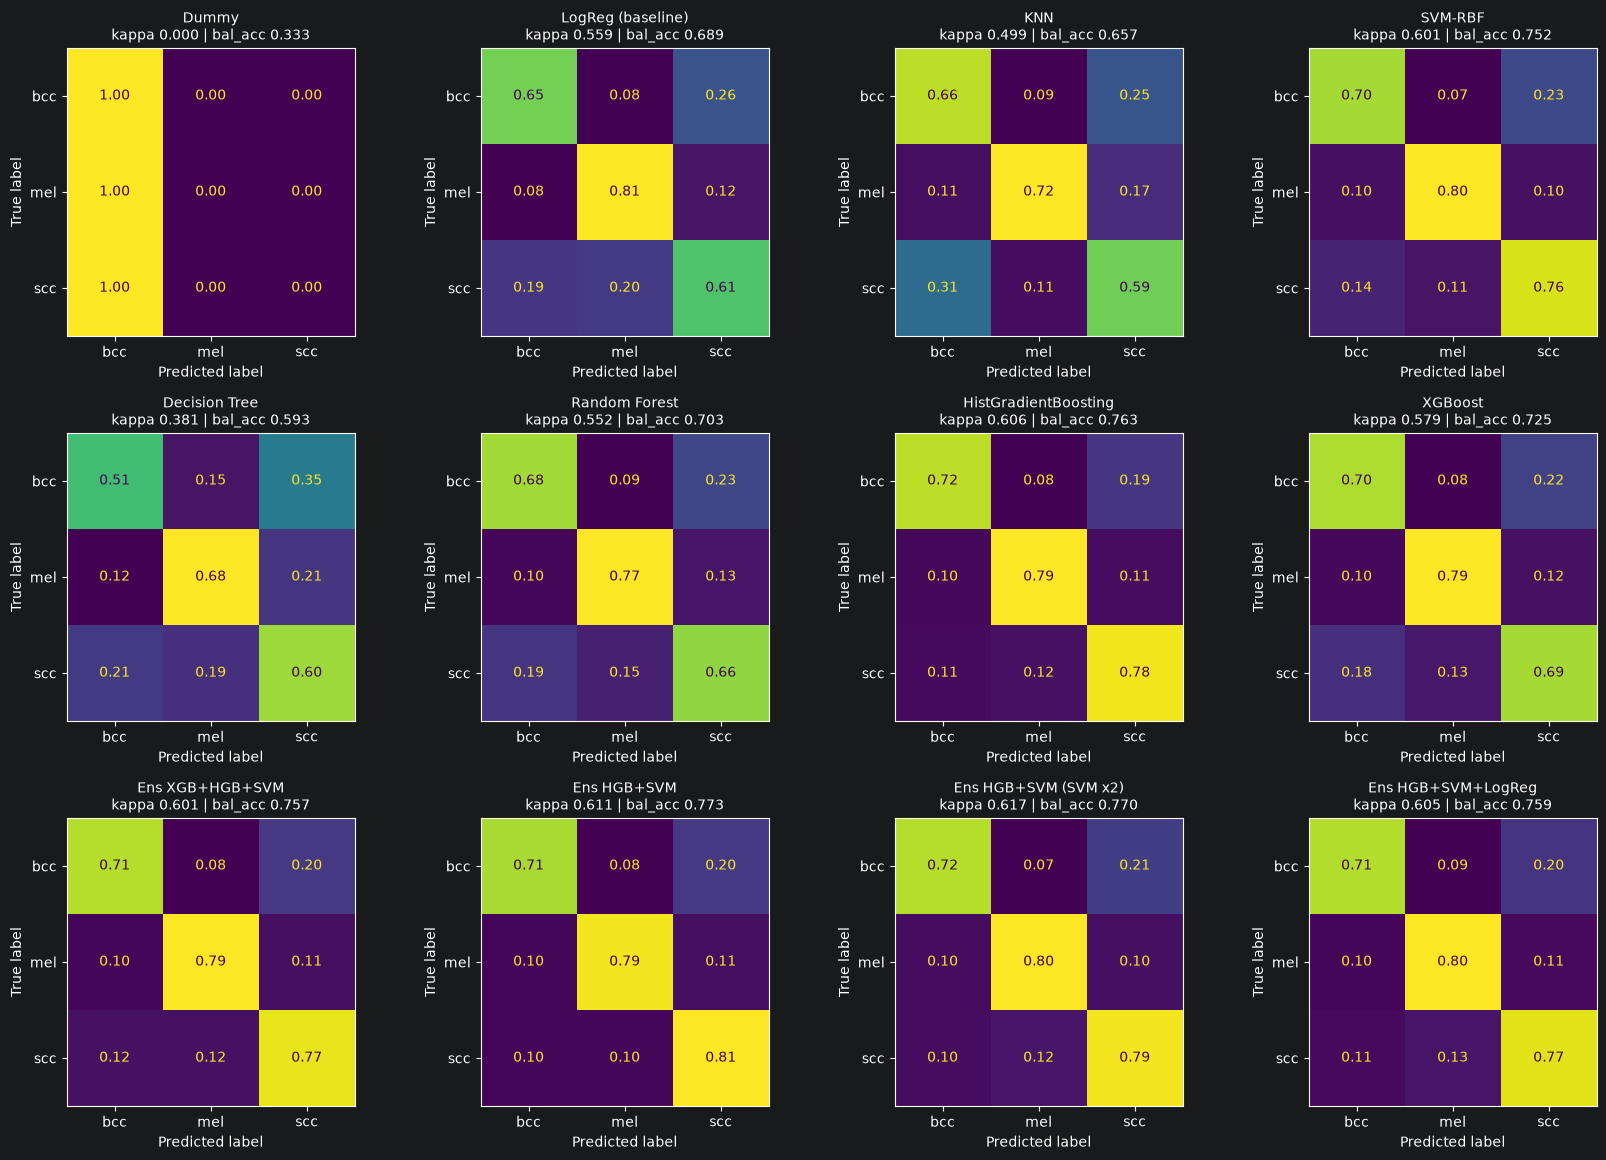

In [13]:
names = list(fitted)
nc = 4
nr = int(np.ceil(len(names) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(4.2 * nc, 3.9 * nr), squeeze=False)
for ax, name in zip(axs.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(yva, preds[name], labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                            normalize="true", values_format=".2f", ax=ax, colorbar=False)
    ax.set_title(f"{name}\nkappa {val_res.loc[name, 'kappa']:.3f} | bal_acc {val_res.loc[name, 'bal_acc']:.3f}", fontsize=10)
for ax in axs.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

### Mejor modelo (elegido por CV): detalle

Mejor modelo en CV: Ens HGB+SVM (SVM x2)

              precision    recall  f1-score   support

         bcc      0.829     0.721     0.771       498
         mel      0.920     0.801     0.856       678
         scc      0.300     0.787     0.434        94

    accuracy                          0.769      1270
   macro avg      0.683     0.770     0.687      1270
weighted avg      0.839     0.769     0.792      1270



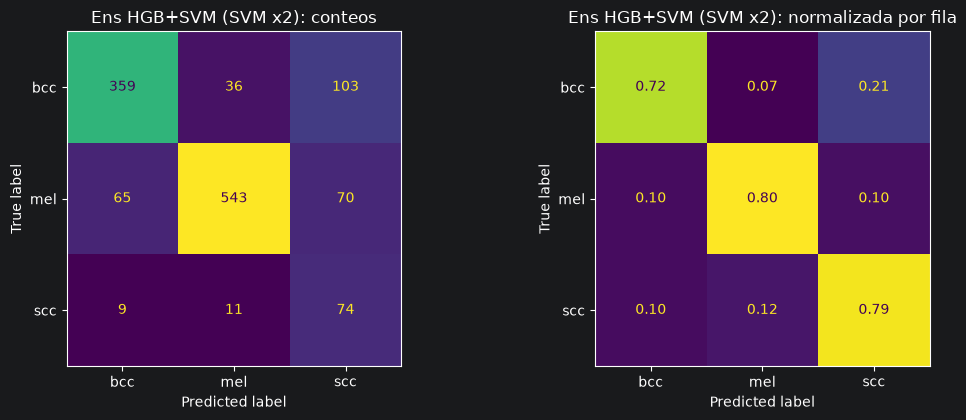

In [14]:
print(f"Mejor modelo en CV: {best}\n")
print(classification_report(yva, preds[best], target_names=CLASSES, digits=3))

fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, norm, fmt, title in [(axs[0], None, "d", "conteos"), (axs[1], "true", ".2f", "normalizada por fila")]:
    ConfusionMatrixDisplay.from_predictions(yva, preds[best], labels=list(range(len(CLASSES))), display_labels=CLASSES,
                                            normalize=norm, values_format=fmt, ax=ax, colorbar=False)
    ax.set_title(f"{best}: {title}")
plt.tight_layout(); plt.show()

### Curvas precision-recall (val)
Con clases desbalanceadas, la curva PR es más informativa que la ROC para la clase minoritaria: la ROC usa la tasa de
falsos positivos, que casi no se mueve porque SCC tiene muchísimos negativos (MEL + BCC); la PR usa la **precisión**,
que sí cae con cada falso positivo. El nivel del azar en PR es la **prevalencia** de la clase (línea discontinua),
no 0.5 como en la ROC.

- Izquierda: el mejor modelo, una curva por clase (one-vs-rest).
- Derecha: SCC para todos los modelos.
- El punto marca dónde cae la predicción actual (argmax), es decir, el recall y la precisión que se obtienen hoy.

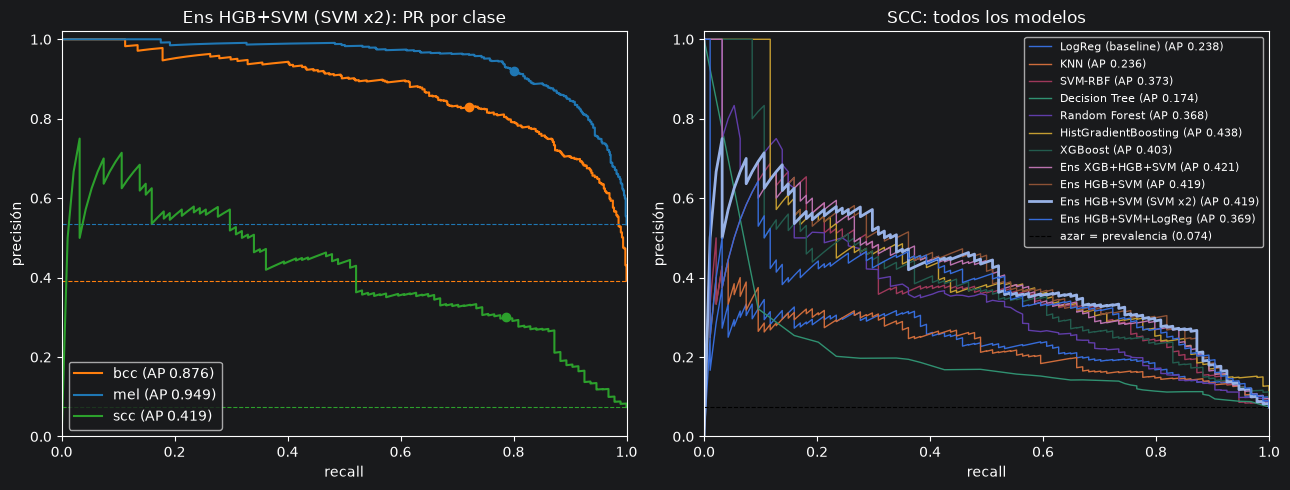

In [15]:
Yva = label_binarize(yva, classes=list(range(len(CLASSES))))
colors = {"mel": "#1f77b4", "bcc": "#ff7f0e", "scc": "#2ca02c"}
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for j, c in enumerate(CLASSES):
    prec, rec, _ = precision_recall_curve(Yva[:, j], probas[best][:, j])
    ap = average_precision_score(Yva[:, j], probas[best][:, j])
    axs[0].plot(rec, prec, color=colors.get(c), label=f"{c} (AP {ap:.3f})")
    axs[0].axhline(Yva[:, j].mean(), color=colors.get(c), ls="--", lw=0.8)
    hit = preds[best] == j
    if hit.any():
        axs[0].plot(recall_score(Yva[:, j], hit), (Yva[hit, j]).mean(), "o", color=colors.get(c))
axs[0].set(xlabel="recall", ylabel="precisión", title=f"{best}: PR por clase", xlim=(0, 1), ylim=(0, 1.02))
axs[0].legend(loc="lower left")

j = CLASSES.index("scc")
for name in fitted:
    if name == "Dummy":
        continue
    prec, rec, _ = precision_recall_curve(Yva[:, j], probas[name][:, j])
    ap = average_precision_score(Yva[:, j], probas[name][:, j])
    axs[1].plot(rec, prec, lw=2 if name == best else 1, label=f"{name} (AP {ap:.3f})")
axs[1].axhline(Yva[:, j].mean(), color="k", ls="--", lw=0.8, label=f"azar = prevalencia ({Yva[:, j].mean():.3f})")
axs[1].set(xlabel="recall", ylabel="precisión", title="SCC: todos los modelos", xlim=(0, 1), ylim=(0, 1.02))
axs[1].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

### Guardar los modelos
Se guarda cada modelo final (entrenado con todo train) en `ml_results_multiclass/models/` como un `.joblib` con el **pipeline completo**
(imputación → selección → escalado → modelo), más una copia del mejor como `best_model.joblib` y un `models_info.json`
con la lista de features (en orden), las etiquetas, el remuestreo usado, las métricas en val y las versiones de las
librerías. Los pipelines guardados no incluyen el sampler.
(`*.joblib` está en el `.gitignore`: no se suben a GitHub.)

Para usarlos después (por ejemplo con las features del test), hacen falta **las mismas versiones** de sklearn / xgboost:
```python
import json, joblib, pandas as pd
d = ROOT / "ml" / "ml_results_multiclass" / "models"
info = json.load(open(d / "models_info.json", encoding="utf-8"))
model = joblib.load(d / "best_model.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]     # mismas columnas, mismo orden
pred = model.predict(X_test)                                    # 0 = bcc, 1 = mel, 2 = scc (orden de CLASSES)
```

In [16]:
TASK = "multiclass"
LABELS = dict(enumerate(CLASSES))
SELECTION = "todas las features" if FINAL_K is None else f"top-{FINAL_K} (Random Forest, SelectFromModel)"

import json
import platform
from datetime import datetime

import joblib
import sklearn

MODEL_DIR = OUT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
slug = lambda s: "".join(ch if ch.isalnum() else "_" for ch in s).strip("_").lower()

# cada archivo es el pipeline COMPLETO ya entrenado con todo train:
# imputación -> [selección top-K] -> [escalado] -> modelo. Recibe las features crudas (FEATS, en ese orden).
saved = {}
for name, pipe in fitted.items():
    if name == "Dummy":
        continue
    path = MODEL_DIR / f"{slug(name)}.joblib"
    joblib.dump(pipe, path, compress=3)
    saved[name] = path.name
joblib.dump(fitted[best], MODEL_DIR / "best_model.joblib", compress=3)

# comprobación: el modelo recargado predice exactamente lo mismo en val
assert (joblib.load(MODEL_DIR / "best_model.joblib").predict(Xva) == preds[best]).all()

try:
    import xgboost
    xgb_version = xgboost.__version__
except Exception:
    xgb_version = None

info = {
    "task": TASK,
    "created": datetime.now().isoformat(timespec="seconds"),
    "best_model": best,
    "files": {**saved, "best": "best_model.joblib"},
    "labels": LABELS,
    "feature_selection": SELECTION,
    "resampling": repr(SAMPLER),       # solo se usó al entrenar
    "n_features_in": len(FEATS),
    "features": FEATS,                                   # columnas de entrada, en este orden
    "train_csv": str(TRAIN_CSV),
    "val_metrics": val_res.reset_index().to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgb_version,
                 "numpy": np.__version__, "pandas": pd.__version__},
}
(MODEL_DIR / "models_info.json").write_text(json.dumps(info, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

print(f"Modelos guardados en {MODEL_DIR}  (mejor: {best} -> best_model.joblib)\n")
for f in sorted(MODEL_DIR.glob("*")):
    print(f"  {f.name:<35s} {f.stat().st_size / 1e6:7.1f} MB")

Modelos guardados en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_multiclass_rus\models  (mejor: Ens HGB+SVM (SVM x2) -> best_model.joblib)

  best_model.joblib                       4.7 MB
  decision_tree.joblib                    0.0 MB
  ens_hgb_svm.joblib                      4.7 MB
  ens_hgb_svm__svm_x2.joblib              4.7 MB
  ens_hgb_svm_logreg.joblib               4.7 MB
  ens_xgb_hgb_svm.joblib                  5.4 MB
  histgradientboosting.joblib             1.4 MB
  knn.joblib                              3.9 MB
  logreg__baseline.joblib                 0.5 MB
  models_info.json                        0.0 MB
  random_forest.joblib                    2.4 MB
  svm_rbf.joblib                          3.1 MB
  xgboost.joblib                          0.7 MB


### ¿Qué features usa el mejor modelo?
Importancia por permutación en val (caída del **kappa** al barajar cada feature). Si hay top-K, solo se
permutan las K seleccionadas.

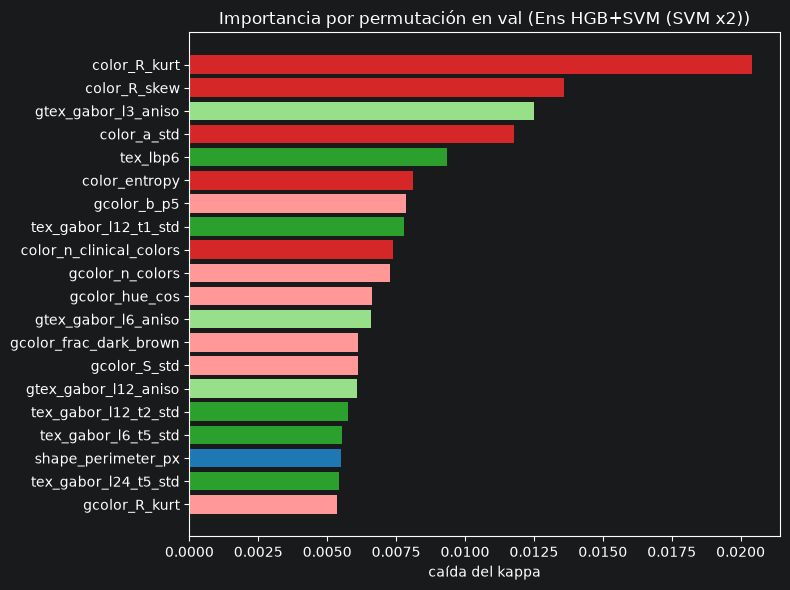

Importancia total por familia: {'color': 0.136, 'gcolor': 0.157, 'gtex': 0.209, 'shape': 0.112, 'tex': 0.242}


In [17]:
pipe = fitted[best]
if "sel" in pipe.named_steps:
    sel = pipe.named_steps["sel"].get_support()
    X_pi, est_pi, names_pi = pipe.named_steps["imp"].transform(Xva)[:, sel], pipe[2:], np.array(FEATS)[sel]
else:
    X_pi, est_pi, names_pi = pipe.named_steps["imp"].transform(Xva), pipe[1:], np.array(FEATS)
pi = permutation_importance(est_pi, X_pi, yva, scoring=make_scorer(cohen_kappa_score), n_repeats=5,
                            random_state=SEED, n_jobs=N_JOBS)
pi = pd.Series(pi.importances_mean, index=names_pi).sort_values(ascending=False)
pi.rename("importancia").to_csv(OUT_DIR / "permutation_importance_best.csv")
top = pi.head(20)[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top.index, top.values, color=[FAM_COLOR[family(c)] for c in top.index])
plt.title(f"Importancia por permutación en val ({best})")
plt.xlabel("caída del kappa"); plt.tight_layout(); plt.show()
print("Importancia total por familia:", pi.groupby(lambda c: family(c)).sum().round(3).to_dict())

## 5. Control de sesgo: ¿se puede adivinar la clase solo con la resolución de la imagen?
Si la resolución original (que delata el dataset de origen: HAM10000, BCN20000, MSK...) ya predice bien la clase, parte
del rendimiento puede venir de la fuente y no de la lesión. Usa `processed/manifest.csv` (`orig_h`, `orig_w`).

In [18]:
man_path = ROOT / "processed" / "manifest.csv"
if not man_path.exists():
    print(f"No encuentro {man_path}: se omite este control.")
else:
    man = pd.read_csv(man_path).drop_duplicates("name").set_index("name")
    cols = ["orig_h", "orig_w"]
    m_tr, m_va = man.reindex(tr["name"])[cols].to_numpy(), man.reindex(va["name"])[cols].to_numpy()
    g = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED).fit(m_tr, ytr)
    p = g.predict(m_va)
    print(f"Solo con la resolución original -> val kappa {cohen_kappa_score(yva, p):.3f}, "
          f"bal_acc {balanced_accuracy_score(yva, p):.3f}\n")
    res_str = man.reindex(va["name"])["orig_w"].astype("Int64").astype(str) + "x" + \
              man.reindex(va["name"])["orig_h"].astype("Int64").astype(str)
    ct = pd.crosstab(res_str.to_numpy(), va["subtype"].to_numpy())
    print(ct.reindex(columns=CLASSES).loc[ct.sum(axis=1).sort_values(ascending=False).index].head(10).to_string())

    rows = []
    for r, idx in pd.Series(range(len(va)), index=res_str.to_numpy()).groupby(level=0):
        idx = idx.to_numpy()
        if len(idx) >= 30 and len(np.unique(yva[idx])) > 1:
            rows.append((r, len(idx), cohen_kappa_score(yva[idx], preds[best][idx]),
                         balanced_accuracy_score(yva[idx], preds[best][idx])))
    print(f"\n{best} por resolución (grupos con >= 30 imágenes):")
    print(pd.DataFrame(rows, columns=["res", "n", "kappa", "bal_acc"]).round(3).to_string(index=False))

No encuentro C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\processed\manifest.csv: se omite este control.


## 6. Modelo final para el test: reentrenar con train + val
Una vez decidido todo con la CV (parámetros, features, modelo o ensemble, factores de decisión) y comprobado en val, se
reentrena el **mismo** pipeline con **train + val** (25 % más de datos, y 94 SCC reales más). Val ya no puede evaluar este
modelo (lo ha visto), así que su rendimiento esperado es el de val o algo mejor.

Se guarda en `OUT_DIR/models/final_model_trainval.joblib` junto con `final_model_trainval.json` (features en orden,
etiquetas y factores de decisión). Para predecir el test:

```python
import json, joblib, numpy as np, pandas as pd
d = ROOT / "ml" / "<carpeta de resultados de este notebook>" / "models"
info = json.load(open(d / "final_model_trainval.json", encoding="utf-8"))
model = joblib.load(d / "final_model_trainval.joblib")
X_test = pd.read_csv("features_test.csv")[info["features"]]          # mismas columnas, mismo orden
if hasattr(model, "predict_proba"):
    P = model.predict_proba(X_test)
else:                                                                # SVM sin probabilidades: softmax de decision_function
    d_ = model.decision_function(X_test); P = np.exp(d_ - d_.max(1, keepdims=True)); P /= P.sum(1, keepdims=True)
pred = np.argmax(P * np.array(info["decision_weights"]), axis=1)     # 0 = bcc, 1 = mel, 2 = scc
labels = [info["labels"][str(i)] for i in pred]
```

In [19]:
import joblib

FIT_TRAINVAL = True

if FIT_TRAINVAL:
    Xall = pd.concat([Xtr, Xva], ignore_index=True)
    yall = np.r_[ytr, yva]
    prep_all = make_prep(FINAL_K, n_jobs=N_JOBS).fit(Xall, yall)
    head_all = fit_head(*ALL_SPECS[best], prep_all.transform(Xall), yall)
    final_pipe = Pipeline(prep_all.steps + [s for s in head_all.steps if s[0] != "sampler"])

    MODEL_DIR = OUT_DIR / "models"
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    joblib.dump(final_pipe, MODEL_DIR / "final_model_trainval.joblib", compress=3)
    final_info = {"model": best, "trained_on": f"train + val ({len(yall)} imágenes)",
                  "feature_selection": str(('todas' if FINAL_K is None else f'top-{FINAL_K}')), "params": best_params,
                  "decision_weights": DECISION_W.tolist(), "labels": dict(enumerate(CLASSES)), "features": FEATS,
                  "cv_kappa": float(res_cv.loc[best, "_main"]), "val_kappa": float(val_res.loc[best, "kappa"])}
    (MODEL_DIR / "final_model_trainval.json").write_text(json.dumps(final_info, indent=2, ensure_ascii=False, default=str),
                                                         encoding="utf-8")
    counts_all = pd.Series(yall).map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES).to_dict()
    print(f"Modelo final: {best} | entrenado con {len(yall)} imágenes {counts_all}")
    print(f"factores de decisión: {dict(zip(CLASSES, DECISION_W.round(2)))}")
    print(f"guardado en {MODEL_DIR / 'final_model_trainval.joblib'}")

Modelo final: Ens HGB+SVM (SVM x2) | entrenado con 6352 imágenes {'bcc': 2491, 'mel': 3391, 'scc': 470}
factores de decisión: {'bcc': np.float64(1.9), 'mel': np.float64(1.0), 'scc': np.float64(0.5)}
guardado en C:\Users\jcgon\PycharmProjects\Melanoma-Challenge-ML-UdG\ml\ml_results_multiclass_rus\models\final_model_trainval.joblib


## Notas y siguientes pasos
*(Rellenar después de ejecutar.)* Comparar con `ml_multiclass.ipynb` (pesos de clase) y los otros remuestreos
(`ml_results_multiclass*/val_results.csv`): kappa en CV y val, recall de SCC y gap train vs CV.

- Mejor modelo y kappa en CV / val:
- Recall de SCC (la clase minoritaria):
- Posibles mejoras: ajuste de hiperparámetros (`RandomizedSearchCV`) del mejor modelo; ajustar los pesos o los
  umbrales por clase para subir el recall de SCC; probar otros remuestreos o combinaciones (SMOTE + undersampling, `BalancedRandomForest`);
  features específicas de BCC/SCC (vasos, queratina, zonas blancas).